In [41]:
import xarray as xr
import torch
import matplotlib.pyplot as plt
import os

from models import FluxNet
from models import compute_divergence_field

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


# Target grid

Note: we run inference over the full grid, including invalid (off-shelf) points, and then mask out invalid grid cells.

In [42]:
from regions import ROSS_BOUNDS

x_min = ROSS_BOUNDS["x_min"]
x_max = ROSS_BOUNDS["x_max"]
y_min = ROSS_BOUNDS["y_min"]
y_max = ROSS_BOUNDS["y_max"]

In [43]:
target_grid_mask = xr.load_dataset("data/target_grid_mask.nc")

X, Y = xr.broadcast(target_grid_mask.x, target_grid_mask.y)

X_long = X.values.flatten()
Y_long = Y.values.flatten()

# NOTE: Normalise to [0, 1] as model input
X_long = (X_long - x_min) / (x_max - x_min)
Y_long = (Y_long - y_min) / (y_max - y_min)

# mask_long = target_grid_mask.mask.values.flatten()

XY_long_tensor = torch.cat((torch.tensor(X_long).unsqueeze(1), torch.tensor(Y_long).unsqueeze(1)), dim = 1)
print(XY_long_tensor.shape)
print(XY_long_tensor[0:5, :])

# Move data to device (not too big for memory)
XY_long_tensor = XY_long_tensor.to(device)

# Total length
N = XY_long_tensor.shape[0]

torch.Size([4000000, 2])
tensor([[2.5000e-04, 9.9975e-01],
        [2.5000e-04, 9.9925e-01],
        [2.5000e-04, 9.9875e-01],
        [2.5000e-04, 9.9825e-01],
        [2.5000e-04, 9.9775e-01]])


# Load trained model and run inference

In [44]:
# Run inference in batches to avoid memory issues
inference_batch_size = 10_000

# Container for divergence fields from all ensemble members
divergences_over_grid_long = torch.empty((1, N), dtype = torch.float32, device = "cpu")

# Initialise
model_e = FluxNet().to(device)
# Load trained weights
model_e.load_state_dict(torch.load(f"fluxnet_trained_on_all_data/fluxnet_full_model.pth", map_location = device))
# Set model to evaluation mode
model_e.eval()

for i in range(0, N, inference_batch_size):

    # Define end index
    j = min(i + inference_batch_size, N)

    print(f"Processing batch {i} to {j}...")

    # Subset batch
    XY_batch = XY_long_tensor[i : j , :]

    # Enable gradients
    XY_batch = XY_batch.requires_grad_(True)

    flux_predictions_batch = model_e(XY_batch)

    divergences_batch = compute_divergence_field(
        mean_pred = flux_predictions_batch, 
        x_grad = XY_batch)
    
    # Store divergence for this ensemble member
    divergences_over_grid_long[0, i:j] = divergences_batch.detach().cpu().unsqueeze(0)

    del divergences_batch
    del flux_predictions_batch
    del XY_batch
    torch.cuda.empty_cache()

# Save divergence fields for all members processed so far
torch.save(divergences_over_grid_long, "fluxnet_trained_on_all_data/divergences_over_grid_long.pt")

Processing batch 0 to 10000...


/tmp/ipykernel_158141/1481382904.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_e.load_state_dict(torch.load(f"fluxnet_trained_on_all_data/fluxnet_full_model.pth

Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing batch 110000 to 120000...
Processing batch 120000 to 130000...
Processing batch 130000 to 140000...
Processing batch 140000 to 150000...
Processing batch 150000 to 160000...
Processing batch 160000 to 170000...
Processing batch 170000 to 180000...
Processing batch 180000 to 190000...
Processing batch 190000 to 200000...
Processing batch 200000 to 210000...
Processing batch 210000 to 220000...
Processing batch 220000 to 230000...
Processing batch 230000 to 240000...
Processing batch 240000 to 250000...
Processing batch 250000 to 260000...
Processing batch 260000 to 270000...
Processing batch 270000 to 280000...
Processing batch 2

In [45]:
divergences_square = divergences_over_grid_long.reshape(X.shape)
print(f"Divergence field shape: {divergences_square.shape}")

mask_tensor = torch.tensor(target_grid_mask.mask.values.T, device = divergences_square.device)

divergences_square_valid = divergences_square.masked_fill(mask_tensor == 0, float("nan"))
print(f"Number of valid divergence values: {torch.sum(~ torch.isnan(divergences_square_valid)).item()}")

Divergence field shape: torch.Size([2000, 2000])
Number of valid divergence values: 1952477


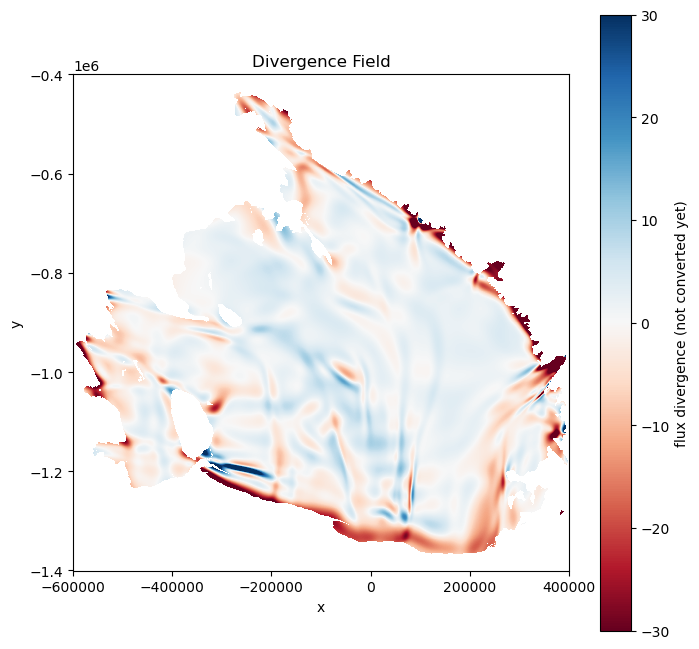

In [46]:
plt.figure(figsize = (8, 8))
plt.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    torch.tensor(X.values).cpu().detach().numpy(), 
    torch.tensor(Y.values).cpu().detach().numpy(),
    divergences_square_valid.cpu().detach().numpy(), 
    cmap = "RdBu", 
    # equivalent to a -3, 3 mapping
    vmax = 30, 
    vmin = -30)
plt.colorbar(label = "flux divergence (not converted yet)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.gca().set_aspect("equal")
plt.show()

# Convert units back to physical units

- **dxy = 1_000_000** because the normalised range [0, 1] presents [0, 1_000_000 m] (1000 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to acheve ~ 1 std i.e. var of flux in both directions.
    - The mean ice thickness of 420 meters * 438 mean ice speed yields ice flux of 183_960 for example.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy**
- This simplifies to **dividing by 10** to get **m / year** units.

# Visualise with MODIS

In [47]:
from paths import path_to_modis
modis_ross = torch.load(path_to_modis, weights_only = False)

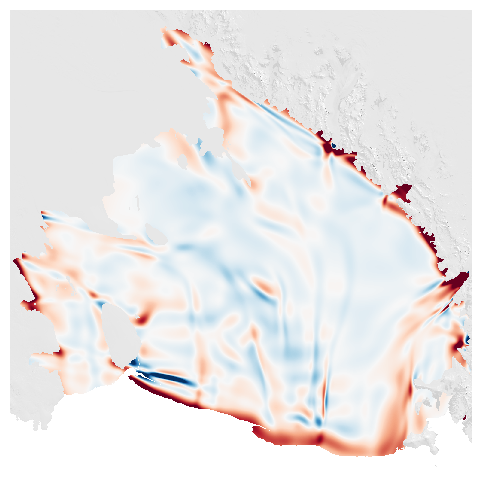

In [48]:
vis_again = True

# Only rerun if needed
if vis_again :

    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        modis_ross[2],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.4,
        zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
        # NOTE: 2D inputs
        # NOTE: Take original coords
        torch.tensor(X.values).cpu().detach().numpy(), 
        torch.tensor(Y.values).cpu().detach().numpy(),
        # Scale conversion
        divergences_square_valid.cpu().detach().numpy() / 10, 
        vmin = -3,
        vmax = 3,
        cmap = "RdBu",
        shading = "auto",
        alpha = 1.0,
        zorder = 1,
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

    fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
    plt.show()

# Generate file / overwrite variable in existing file

In [49]:
path = "data/fluxnet_div_ross.nc"

# make field numpy and scale
# m i.e. / yr
div_np = divergences_square_valid.cpu().detach().numpy() / 10.0 

# ensure (y,x) ordering on the target grid
div_da = xr.DataArray(
    div_np,
    dims = ("y", "x"),
    coords = {"x": target_grid_mask["x"], "y": target_grid_mask["y"]},
    name = "fluxnet_div",
    attrs = {
        "long_name": "Flux divergence (net) converted to metres ice-equivalent per year",
        "units": "m i.e. yr-1",
    },
).transpose("y", "x")  # no-op if already correct

if not os.path.exists(path):
    ds = div_da.to_dataset()
else:
    with xr.open_dataset(path) as _ds:
        ds = _ds.load()
    ds = ds.assign_coords(x = target_grid_mask["x"], y = target_grid_mask["y"])

ds["fluxnet_div"] = div_da

tmp = path + ".tmp"
ds.to_netcdf(tmp, mode = "w")
os.replace(tmp, path)